<div dir="rtl" style="direction: rtl; text-align: right;">

# راهنمای آموزشی حل‌شده
## سری زمانی، K-Means، SOM و شبکه‌ی هاپفیلد

هدف این دفترچه آموزش **چرخه‌ی کامل حل مسئله با داده** است: تعریف مسئله، شناخت داده‌ی خام، پاک‌سازی، تبدیل داده به ورودی مناسب الگوریتم، آموزش مدل و تفسیر نتیجه. در هر بخش توضیح می‌دهیم چرا یک مرحله را انجام می‌دهیم، نه اینکه فقط کد آن را اجرا کنیم.

### مسیر یادگیری
1. سری زمانی: پیش‌بینی دمای کمینه‌ی روز بعد با استفاده از تاریخچه.
2. K-Means: گروه‌بندی پنگوئن‌ها با چهار ویژگی عددی، بدون استفاده از نام گونه در آموزش.
3. SOM: نمایش همان داده‌ی چندبعدی روی شبکه‌ی دوبعدی و بررسی همسایگی نمونه‌ها.
4. Hopfield: ذخیره‌ی الگوهای دوقطبی و بازیابی تصویر خراب‌شده.

### چرخه‌ی کاری که در هر بخش تکرار می‌شود
- **تعریف مسئله:** ورودی مدل چیست و خروجی مورد انتظار چیست؟
- **EDA یا بررسی اکتشافی:** ابعاد، نوع ستون‌ها، مقدارهای گمشده، توزیع و نمودار داده‌ی خام را بررسی می‌کنیم.
- **پاک‌سازی:** داده‌ی تکراری، نامعتبر یا ناقص را مدیریت می‌کنیم.
- **آماده‌سازی ورودی:** ویژگی می‌سازیم، ستون مناسب انتخاب می‌کنیم، مقیاس‌ها را همسان می‌کنیم یا تصویر را به حالت دودویی تبدیل می‌کنیم.
- **مدل‌سازی و ارزیابی:** الگوریتم را اجرا می‌کنیم و با معیار سازگار با نوع مسئله نتیجه را بررسی می‌کنیم.

مثال اول از داده‌ی دمای روزانه استفاده می‌کند تا مراحل ساخت ویژگی زمانی و مقایسه‌ی دو مدل رگرسیون روشن باشد. مسئله‌ی آن عمداً از داده‌ی بار الکتریکی در دفترچه‌ی پرسش‌های پروژه جداست.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱) سری زمانی — پیش‌بینی دمای کمینه‌ی روز بعد

### مسئله
در این مثال، هر روز یک مقدار از دمای کمینه ثبت شده است و می‌خواهیم مقدار روز بعد را پیش‌بینی کنیم. ستون `value` متغیر هدف است.

ترتیب زمان در سری زمانی حیاتی است. مقدار روزهای آینده نباید هنگام آموزش برای پیش‌بینی گذشته در دسترس باشد. به همین دلیل داده‌ی قدیمی‌تر برای آموزش، بازه‌ی بعدی برای اعتبارسنجی و بازه‌ی انتهایی برای آزمون استفاده می‌شود؛ تقسیم تصادفی نداریم.

### دریافت و مشاهده‌ی داده‌ی خام
در سلول بعد کتابخانه‌های موردنیاز همه‌ی بخش‌های دفترچه وارد می‌شوند. سپس مجموعه‌ی دمای روزانه خوانده می‌شود، ستون تاریخ به نوع زمانی تبدیل می‌شود و زمان را شاخص جدول قرار می‌دهیم. تعداد ردیف‌ها، مقدارهای گمشده و نمودار خام را بررسی می‌کنیم.

</div>

Raw shape: (3650, 1)
Data types:
value    float64
dtype: object
Missing values:
value    0
dtype: int64


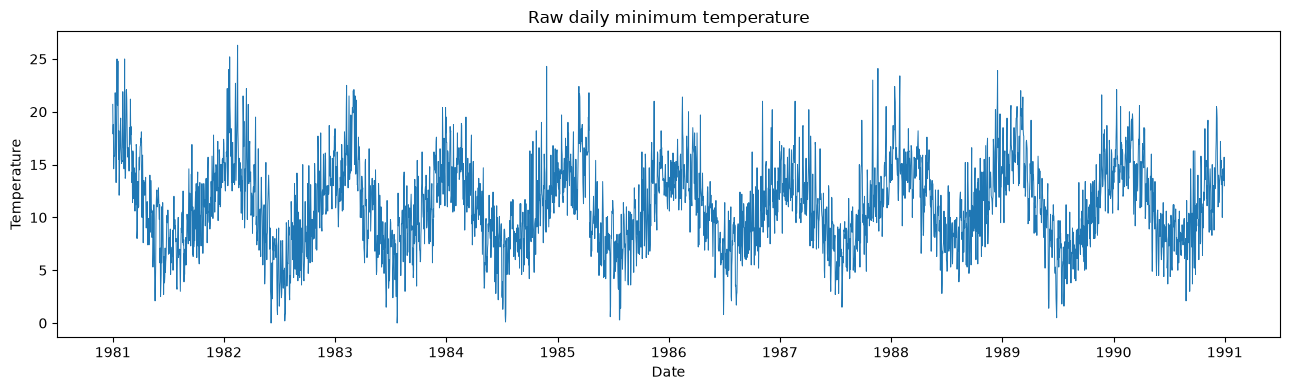

In [1]:
# Imports used throughout this notebook
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import load_digits
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    silhouette_score,
    adjusted_rand_score,
)

from minisom import MiniSom

# Daily minimum temperature teaching dataset.
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
ts = pd.read_csv(url, parse_dates=["Date"]).rename(
    columns={"Date": "timestamp", "Temp": "value"}
)
ts = ts.sort_values("timestamp").set_index("timestamp")

print("Raw shape:", ts.shape)
print("Data types:")
print(ts.dtypes)
print("Missing values:")
print(ts.isna().sum())

plt.figure(figsize=(13, 4))
plt.plot(ts.index, ts["value"], linewidth=0.7)
plt.title("Raw daily minimum temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### پاک‌سازی داده‌ی زمانی

1. ردیف‌های دارای timestamp تکراری حذف می‌شوند. در این مثال اولین مقدار حفظ می‌شود؛ در کاربرد واقعی باید علت تکرار بررسی شود.
2. با `asfreq("D")` شاخص روزانه می‌سازیم. تاریخ‌های غایب به ردیف‌هایی با مقدار گمشده تبدیل می‌شوند.
3. مقدارها به نوع عددی تبدیل می‌شوند؛ موارد غیرقابل‌تبدیل با `errors="coerce"` به NaN تبدیل خواهند شد.
4. در این مجموعه‌ی دما، مقادیر خارج از بازه‌ی ۳۰- تا ۵۰ را نامعتبر فرض می‌کنیم. این حد مخصوص مثال حاضر است و برای داده‌ی حوزه‌ی دیگر باید با دانش حوزه تعیین شود.
5. مقدار گمشده را با آخرین مقدار معتبر قبلی پر می‌کنیم (forward fill). در پیش‌بینی آینده این روش بهتر از پرکردن با میانگین دو طرف است؛ چون از مقدار آینده برای بازسازی گذشته استفاده نمی‌کند. اگر در ابتدای سری سابقه‌ای وجود نداشته باشد، آن ردیف حذف می‌شود.

در تحلیل توصیفی گاهی interpolation دوطرفه قابل قبول است، اما برای مسئله‌ی پیش‌بینی ممکن است نشت اطلاعات ایجاد کند. پس از پاک‌سازی نمودار را دوباره رسم می‌کنیم.

</div>

Values outside the accepted range: 2
Missing values filled: 2
Cleaned shape: (3652, 1)
Remaining missing values: 0


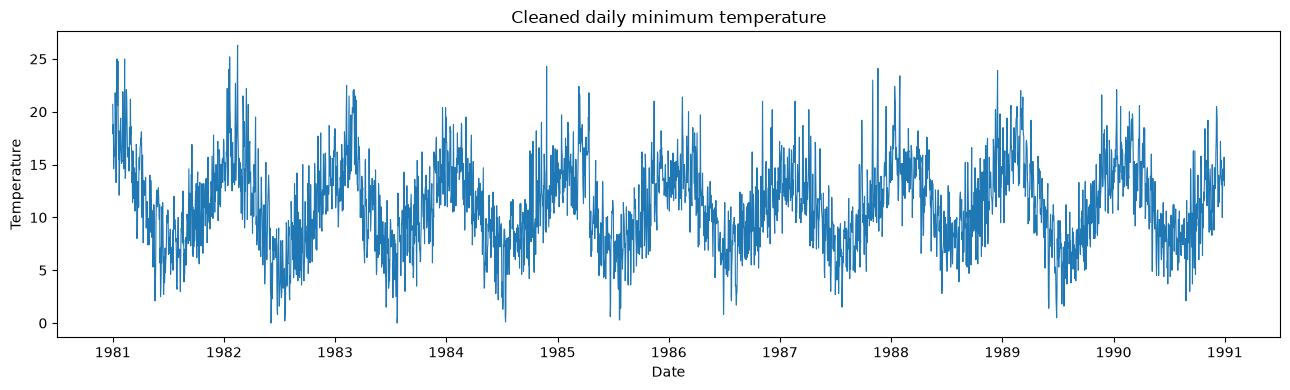

In [2]:
# Remove duplicate timestamps and create a complete daily index.
ts = ts[~ts.index.duplicated(keep="first")].asfreq("D")
ts["value"] = pd.to_numeric(ts["value"], errors="coerce")

# These physical limits are specific to this temperature dataset.
invalid_values = ~ts["value"].between(-30, 50)
print("Values outside the accepted range:", int(invalid_values.sum()))
ts.loc[invalid_values, "value"] = np.nan

missing_before_fill = int(ts["value"].isna().sum())
ts["value"] = ts["value"].ffill()
ts = ts.dropna(subset=["value"])

print("Missing values filled:", missing_before_fill)
print("Cleaned shape:", ts.shape)
print("Remaining missing values:", int(ts["value"].isna().sum()))

plt.figure(figsize=(13, 4))
plt.plot(ts.index, ts["value"], linewidth=0.8)
plt.title("Cleaned daily minimum temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### ساخت ویژگی‌ها (Feature Engineering)

مدل رگرسیون به‌خودی‌خود مفهوم «دیروز»، «هفته‌ی قبل» یا «فصل سال» را نمی‌داند؛ باید این اطلاعات را به ستون‌های عددی تبدیل کنیم. برای پیش‌بینی دمای روز t از این ورودی‌ها استفاده می‌کنیم:

| ویژگی | مفهوم |
|---|---|
| `lag_1` | دمای روز قبل |
| `lag_7` | دمای هفت روز قبل |
| `rolling_7` | میانگین هفت مقدار قبلی |
| `lag_365` | دمای تقریباً همان روز در سال قبل |
| `year_sin`, `year_cos` | موقعیت چرخه‌ای روز در سال |

نکته‌ی مهم `shift(1)` در `rolling_7` است. اگر میانگین متحرک را بدون جابه‌جایی حساب کنیم، ممکن است مقدار همان روز هدف هم وارد ویژگی شود و مدل پاسخ را از ورودی ببیند. با `shift(1)`، پنجره فقط روزهای قبل را می‌بیند.

برای نمایش فصل، شماره‌ی روز در سال را به دو ویژگی سینوسی و کسینوسی تبدیل می‌کنیم. این ویژگی‌ها کمک می‌کنند روزهای نزدیک به ابتدای سال و انتهای سال از نظر چرخه‌ای نزدیک باشند.

پس از ساخت ویژگی‌ها، ردیف‌هایی که سابقه‌ی کافی ندارند حذف می‌شوند. سپس داده را به ترتیب زمان به سه قسمت ۷۰٪ آموزش، ۱۵٪ اعتبارسنجی و ۱۵٪ آزمون تقسیم می‌کنیم. اعتبارسنجی برای انتخاب epoch شبکه و عمق درخت استفاده می‌شود؛ آزمون تا پایان دست‌نخورده می‌ماند.

در این مثال ارزیابی **یک‌گام‌به‌جلو با به‌روزرسانی روزانه** است: برای پیش‌بینی هر روز آزمون، مقدارهای واقعی روزهای قبل در دسترس فرض می‌شوند. این با پیش‌بینی بازگشتی کل سال آینده بدون مشاهده‌ی مقدارهای واقعی میانی تفاوت دارد.

</div>

In [3]:
# Create lagged, rolling, and annual-cycle features using past information only.
model_data = ts.copy()

model_data["lag_1"] = model_data["value"].shift(1)
model_data["lag_7"] = model_data["value"].shift(7)
model_data["rolling_7"] = (
    model_data["value"].shift(1).rolling(window=7, min_periods=7).mean()
)
model_data["lag_365"] = model_data["value"].shift(365)

day_of_year = model_data.index.dayofyear.to_numpy()
model_data["year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
model_data["year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

FEATURES = [
    "lag_1",
    "lag_7",
    "rolling_7",
    "lag_365",
    "year_sin",
    "year_cos",
]

# Keep the simple previous-day prediction as a baseline, not a model feature.
model_data["baseline_lag_1"] = model_data["value"].shift(1)

data = model_data.dropna(
    subset=FEATURES + ["value", "baseline_lag_1"]
).copy()

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert np.isclose(TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0)

train_end = int(TRAIN_RATIO * len(data))
val_end = int((TRAIN_RATIO + VAL_RATIO) * len(data))

train = data.iloc[:train_end].copy()
validation = data.iloc[train_end:val_end].copy()
test = data.iloc[val_end:].copy()

print("Input features:", FEATURES)
print("Input count:", len(FEATURES))
print("Training input shape:", train[FEATURES].shape)
print("Training target shape:", train["value"].shape)
print("Train / validation / test rows:",
      len(train), "/", len(validation), "/", len(test))
print("Train period:", train.index.min().date(), "to", train.index.max().date())
print("Validation period:", validation.index.min().date(), "to", validation.index.max().date())
print("Test period:", test.index.min().date(), "to", test.index.max().date())

Input features: ['lag_1', 'lag_7', 'rolling_7', 'lag_365', 'year_sin', 'year_cos']
Input count: 6
Training input shape: (2300, 6)
Training target shape: (2300,)
Train / validation / test rows: 2300 / 493 / 494
Train period: 1982-01-01 to 1988-04-18
Validation period: 1988-04-19 to 1989-08-24
Test period: 1989-08-25 to 1990-12-31


<div dir="rtl" style="direction: rtl; text-align: right;">

### آموزش MLP و مقایسه با درخت تصمیم

ابتدا یک **شبکه‌ی عصبی پیش‌خور MLP** آموزش می‌دهیم. شش ویژگی وارد شبکه می‌شوند، دو لایه‌ی پنهان آن‌ها را ترکیب می‌کنند و یک نورون خروجی دمای روز بعد را پیش‌بینی می‌کند:
$
6\ inputs\rightarrow 64\ hidden\rightarrow 32\ hidden\rightarrow 1\ output
$
پارامترهای اصلی MLP:

| پارامتر | مقدار نمونه | معنی |
|---|---:|---|
| `HIDDEN_LAYER_SIZES` | (64, 32) | تعداد نورون‌های لایه‌های پنهان |
| `ACTIVATION` | tanh | تابع فعال‌سازی لایه‌های پنهان |
| `SOLVER` | Adam | روش بهینه‌سازی وزن‌ها |
| `LEARNING_RATE` | 0.001 | اندازه‌ی گام به‌روزرسانی وزن‌ها |
| `ALPHA` | 0.0005 | ضریب منظم‌سازی برای کنترل بیش‌برازش |
| `BATCH_SIZE` | 32 | تعداد نمونه در هر دسته‌ی آموزش |
| `MAX_EPOCHS` | 300 | بیشترین تعداد epoch |
| `PATIENCE` | 30 | توقف اگر خطای اعتبارسنجی بهتر نشود |

ویژگی‌ها و مقدار هدف را با `StandardScaler` مقیاس‌بندی می‌کنیم. مقیاس‌ساز فقط روی train برازش می‌شود تا اطلاعات validation یا test وارد preprocessing نشود. برای انتخاب بهترین نسخه‌ی شبکه، خطای validation را پس از هر epoch محاسبه می‌کنیم و بهترین وزن‌ها را نگه می‌داریم.

سپس یک **Decision Tree Regressor** با همان ورودی‌ها آموزش می‌دهیم. عمق درخت را با مقایسه‌ی چند مقدار روی validation انتخاب می‌کنیم. درخت به استانداردسازی نیاز ندارد، چون بر اساس شرط‌هایی مانند «آیا ویژگی از یک آستانه بزرگ‌تر است؟» داده را تقسیم می‌کند.

در پایان، هر دو مدل را روی **همان بازه‌ی test** و در برابر baseline مقدار روز قبل مقایسه می‌کنیم. معیارهای MAE و RMSE هرچه کمتر باشند بهترند. درخت تصمیم ممکن است روی این مجموعه بهتر عمل کند یا نکند؛ نتیجه را باید از روی آزمون دید، نه با فرض قبلی.

</div>

MLP architecture: 6 inputs -> (64, 32) -> 1 output
Activation: tanh | Solver: adam
Learning rate: 0.001 | Alpha: 0.0005 | Batch size: 32
Best MLP epoch: 26 of 56
Best MLP validation MSE (scaled target): 0.31109
Selected decision-tree max_depth: 5
Decision-tree validation RMSE: 2.4621

Test-set comparison (lower is better):


,MAE,RMSE
MLP,1.7602,2.2497
Decision tree,1.7811,2.2792
Previous-day baseline,2.0650,2.6168


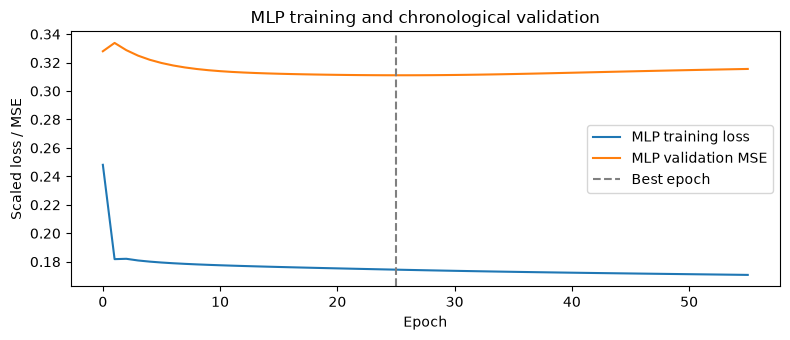

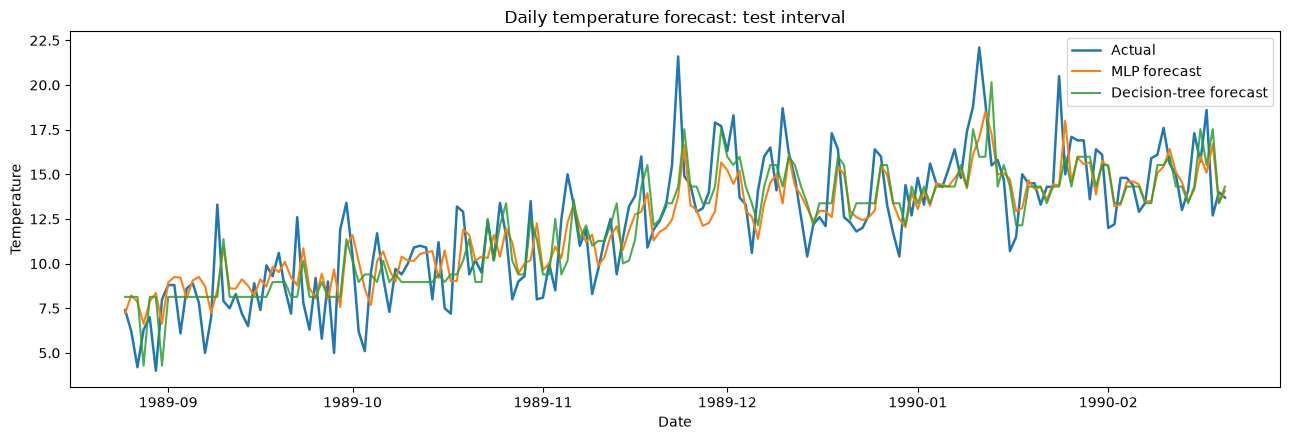

Decision-tree feature importance:


,importance
rolling_7,0.636
lag_1,0.296
year_cos,0.037
lag_365,0.015
year_sin,0.009
lag_7,0.007


Interpretation: compare both learned models with the previous-day baseline. The best model is the one with the lower test error, while the forecast plot shows whether it follows the seasonal changes and short-term fluctuations.


In [4]:
# Main MLP hyperparameters: these are the values students can experiment with.
HIDDEN_LAYER_SIZES = (64, 32)
ACTIVATION = "tanh"
SOLVER = "adam"
LEARNING_RATE = 0.001
ALPHA = 0.0005
BATCH_SIZE = 32
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 12345678

# Use chronological partitions created in the previous cell.
X_train_raw = train[FEATURES].to_numpy(dtype=float)
X_val_raw = validation[FEATURES].to_numpy(dtype=float)
X_test_raw = test[FEATURES].to_numpy(dtype=float)

y_train_raw = train["value"].to_numpy(dtype=float)
y_val_raw = validation["value"].to_numpy(dtype=float)
y_test_raw = test["value"].to_numpy(dtype=float)

# Fit all preprocessing on the training partition only.
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train_raw)
X_val = x_scaler.transform(X_val_raw)
X_test = x_scaler.transform(X_test_raw)

y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train_raw.reshape(-1, 1)).ravel()
y_val = y_scaler.transform(y_val_raw.reshape(-1, 1)).ravel()

# Train one epoch at a time so the chronological validation set controls stopping.
mlp = MLPRegressor(
    hidden_layer_sizes=HIDDEN_LAYER_SIZES,
    activation=ACTIVATION,
    solver=SOLVER,
    alpha=ALPHA,
    batch_size=BATCH_SIZE,
    learning_rate_init=LEARNING_RATE,
    max_iter=1,
    shuffle=True,
    random_state=SEED,
    tol=0.0,
)

best_mlp = None
best_val_mse = np.inf
best_epoch = 0
epochs_without_improvement = 0
train_loss_history = []
val_mse_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.partial_fit(X_train, y_train)

    train_loss_history.append(float(mlp.loss_))
    val_prediction_scaled = mlp.predict(X_val)
    val_mse = float(np.mean((val_prediction_scaled - y_val) ** 2))
    val_mse_history.append(val_mse)

    if val_mse < best_val_mse - 1e-6:
        best_val_mse = val_mse
        best_epoch = epoch
        best_mlp = deepcopy(mlp)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        break

if best_mlp is None:
    raise RuntimeError("The MLP did not produce a validation checkpoint.")

def inverse_temperature_scale(values):
    values = np.asarray(values, dtype=float).reshape(-1, 1)
    return y_scaler.inverse_transform(values).ravel()

mlp_train_pred = inverse_temperature_scale(best_mlp.predict(X_train))
mlp_val_pred = inverse_temperature_scale(best_mlp.predict(X_val))
mlp_test_pred = inverse_temperature_scale(best_mlp.predict(X_test))

# Decision-tree comparison: choose its depth using validation, not test.
TREE_DEPTHS = [3, 5, 8, 12, None]
TREE_MIN_SAMPLES_LEAF = 5
best_tree = None
best_tree_depth = None
best_tree_val_rmse = np.inf

for depth in TREE_DEPTHS:
    candidate_tree = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=TREE_MIN_SAMPLES_LEAF,
        random_state=SEED,
    )
    candidate_tree.fit(X_train_raw, y_train_raw)
    candidate_val_pred = candidate_tree.predict(X_val_raw)
    candidate_val_rmse = float(
        np.sqrt(mean_squared_error(y_val_raw, candidate_val_pred))
    )

    if candidate_val_rmse < best_tree_val_rmse:
        best_tree_val_rmse = candidate_val_rmse
        best_tree = candidate_tree
        best_tree_depth = depth

tree_test_pred = best_tree.predict(X_test_raw)
baseline_test_pred = test["baseline_lag_1"].to_numpy(dtype=float)

def regression_scores(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mse),
    }

comparison = pd.DataFrame(
    {
        "MLP": regression_scores(y_test_raw, mlp_test_pred),
        "Decision tree": regression_scores(y_test_raw, tree_test_pred),
        "Previous-day baseline": regression_scores(y_test_raw, baseline_test_pred),
    }
).T.sort_values("RMSE")

print("MLP architecture: 6 inputs ->", HIDDEN_LAYER_SIZES, "-> 1 output")
print("Activation:", ACTIVATION, "| Solver:", SOLVER)
print("Learning rate:", LEARNING_RATE, "| Alpha:", ALPHA, "| Batch size:", BATCH_SIZE)
print("Best MLP epoch:", best_epoch, "of", len(val_mse_history))
print("Best MLP validation MSE (scaled target):", round(best_val_mse, 5))
print("Selected decision-tree max_depth:", best_tree_depth)
print("Decision-tree validation RMSE:", round(best_tree_val_rmse, 4))
print("\nTest-set comparison (lower is better):")
display(comparison.round(4))

# Compare the validation and training curves to spot underfitting or overfitting.
plt.figure(figsize=(8, 3.5))
plt.plot(train_loss_history, label="MLP training loss")
plt.plot(val_mse_history, label="MLP validation MSE")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="Best epoch")
plt.title("MLP training and chronological validation")
plt.xlabel("Epoch")
plt.ylabel("Scaled loss / MSE")
plt.legend()
plt.tight_layout()
plt.show()

# Show a readable portion of the test interval.
plot_days = min(180, len(test))
plt.figure(figsize=(13, 4.5))
plt.plot(test.index[:plot_days], y_test_raw[:plot_days],
         label="Actual", linewidth=1.8)
plt.plot(test.index[:plot_days], mlp_test_pred[:plot_days],
         label="MLP forecast")
plt.plot(test.index[:plot_days], tree_test_pred[:plot_days],
         label="Decision-tree forecast", alpha=0.85)
# plt.plot(test.index[:plot_days], baseline_test_pred[:plot_days],
#          label="Previous-day baseline", alpha=0.75)
plt.title("Daily temperature forecast: test interval")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.tight_layout()
plt.show()

# The tree can be inspected to understand which inputs were useful for its splits.
tree_importance = pd.Series(
    best_tree.feature_importances_, index=FEATURES
).sort_values(ascending=False)
print("Decision-tree feature importance:")
display(tree_importance.to_frame("importance").round(3))

print(
    "Interpretation: compare both learned models with the previous-day baseline. "
    "The best model is the one with the lower test error, while the forecast plot "
    "shows whether it follows the seasonal changes and short-term fluctuations."
)

<div dir="rtl" style="direction: rtl; text-align: right;">


## ۲) K-Means — خوشه‌بندی پنگوئن‌ها

### مسئله و هدف
می‌خواهیم نمونه‌های پنگوئن را با توجه به اندازه‌گیری‌های فیزیکی‌شان به گروه‌های مشابه تقسیم کنیم. چهار ویژگی عددی داریم: طول نوک، عمق نوک، طول باله و جرم بدن. در این مثال ستون species هم در فایل وجود دارد، اما **آن را به K-Means نمی‌دهیم**. هدف خوشه‌بندی بدون ناظر است: الگوریتم باید فقط از شباهت اندازه‌گیری‌ها گروه‌ها را بسازد.

چرا پنگوئن؟ این داده‌ی واقعی و قابل‌فهم، چند ویژگی عددی با واحدها و مقیاس‌های متفاوت دارد و برای یادگیری مفهوم خوشه‌بندی مناسب است. پروژه‌ی اصلی همین روند را روی پروفایل‌های بار یا رفتار فیدرهای الکتریکی اجرا می‌کند.

### دریافت و بررسی داده‌ی خام
در کد بعدی فقط چهار ستون عددی موردنیاز و ستون گونه را بررسی می‌کنیم. پیش از پاک‌سازی، تعداد ردیف‌ها، مقدارهای گمشده و یک نمودار از دو ویژگی را می‌بینیم. نمودار دوبعدی خام فقط یک نگاه اولیه است؛ چهار ویژگی را هم‌زمان نشان نمی‌دهد.


</div>

Raw rows: 344
Missing values by feature:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64


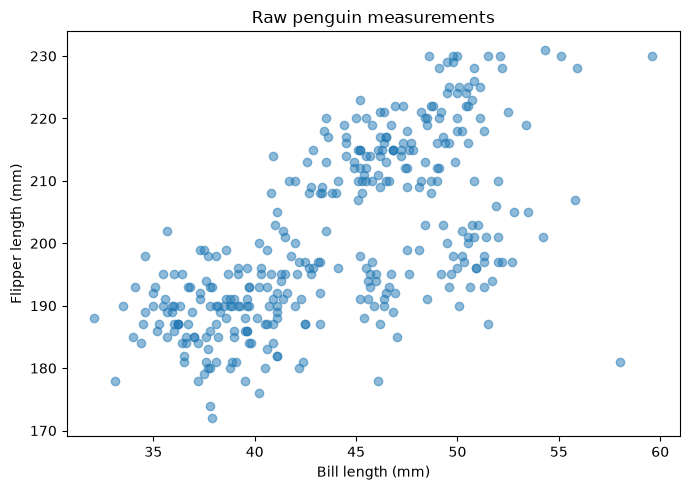

In [5]:
penguins_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins_raw = pd.read_csv(penguins_url)
numeric_cols = ["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]
print("Raw rows:", len(penguins_raw))
print("Missing values by feature:")
print(penguins_raw[numeric_cols].isna().sum())

plt.figure(figsize=(7,5))
plt.scatter(penguins_raw["bill_length_mm"], penguins_raw["flipper_length_mm"], alpha=0.5)
plt.title("Raw penguin measurements")
plt.xlabel("Bill length (mm)"); plt.ylabel("Flipper length (mm)")
plt.tight_layout(); plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">


### پاک‌سازی، استانداردسازی و PCA

ردیف‌هایی که در یکی از چهار ویژگی عددی مقدار گمشده دارند حذف می‌شوند. سپس ماتریس ورودی را می‌سازیم. هر **ردیف** یک پنگوئن و هر **ستون** یک ویژگی است؛ اگر n پنگوئن باقی بماند، شکل ماتریس X برابر n×4 خواهد بود.

چرا استانداردسازی؟ جرم بدن بر حسب گرم ممکن است عددی در حد چند هزار باشد، درحالی‌که طول باله و نوک بر حسب میلی‌متر عددهای کوچک‌تری دارند. K-Means از فاصله‌ی اقلیدسی استفاده می‌کند؛ پس بدون scaling، ویژگی با عدد بزرگ‌تر ممکن است فقط به خاطر واحد اندازه‌گیری بر فاصله غالب شود.

StandardScaler برای هر ستون تبدیل زیر را انجام می‌دهد:
$
z=\frac{x-\mu}{\sigma}
$
میانگین ستون کم می‌شود و نتیجه بر انحراف معیار تقسیم می‌شود؛ بنابراین هر ویژگی تقریباً میانگین صفر و انحراف معیار یک پیدا می‌کند.

#### PCA چه کاری انجام می‌دهد؟
چهار ویژگی داریم، اما نمودار دوبعدی فقط دو محور دارد. PCA محورهای جدیدی پیدا می‌کند که مؤلفه‌های نخست آن‌ها بیشترین واریانس ممکن را حفظ کنند. با n_components=2 هر نمونه را از فضای چهاربعدی به دو مختصات تبدیل می‌کنیم تا قابل رسم شود.

- **X**: داده‌ی استانداردشده با هر چهار ویژگی؛ ورودی اصلی K-Means.
- **X2**: همان ردیف‌ها پس از PCA، اما با دو ستون/مختصات؛ برای نمودار.

در این مثال K-Means را روی X اجرا می‌کنیم، نه X2؛ چون نمی‌خواهیم با کاهش ابعاد، اطلاعات احتمالی دو ویژگی را هنگام خوشه‌بندی دور بریزیم. X و X2 دو مجموعه‌ی نمونه‌ی متفاوت نیستند؛ فقط دو نمایش با تعداد ویژگی متفاوت‌اند. مجموع explained_variance_ratio_ نشان می‌دهد دو مؤلفه‌ی اول چه سهمی از واریانس چهار ویژگی را نگه داشته‌اند.


</div>

Rows after cleaning: 342
Original feature count: 4
X shape (samples, original features): (342, 4)
Scaled feature means: [ 0. -0. -0.  0.]
Scaled feature standard deviations: [1. 1. 1. 1.]
X2 shape (samples, 2 PCA components): (342, 2)
Variance retained by each component: [0.688 0.193]
Total variance retained in 2D: 0.882


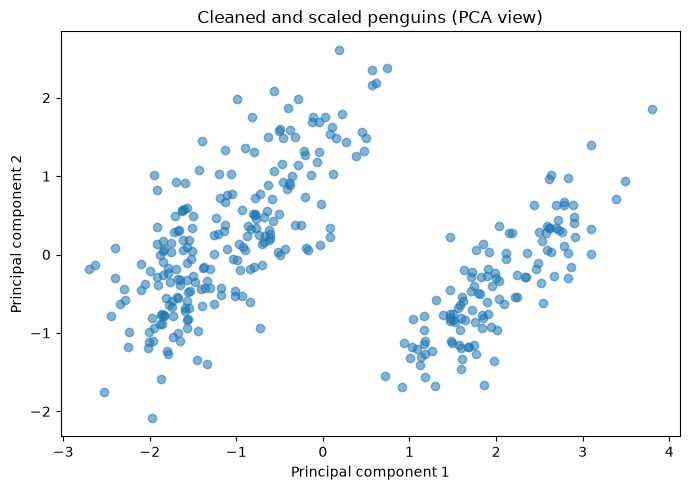

In [6]:

penguins = penguins_raw[numeric_cols + ["species"]].dropna().copy()

scaler = StandardScaler()
X = scaler.fit_transform(penguins[numeric_cols])

print("Rows after cleaning:", len(penguins))
print("Original feature count:", len(numeric_cols))
print("X shape (samples, original features):", X.shape)
print("Scaled feature means:", np.round(X.mean(axis=0), 3))
print("Scaled feature standard deviations:", np.round(X.std(axis=0), 3))

pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X)

print("X2 shape (samples, 2 PCA components):", X2.shape)
print("Variance retained by each component:",
      np.round(pca.explained_variance_ratio_, 3))
print("Total variance retained in 2D:",
      round(float(pca.explained_variance_ratio_.sum()), 3))

plt.figure(figsize=(7,5))
plt.scatter(X2[:, 0], X2[:, 1], alpha=0.55)
plt.title("Cleaned and scaled penguins (PCA view)")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right;">


### اجرای K-Means روی ویژگی‌های اصلی

K-Means به تعداد خوشه‌ها نیاز دارد. هر خوشه یک مرکز (centroid) دارد؛ هر نمونه به نزدیک‌ترین مرکز نسبت داده می‌شود و مراکز با میانگین‌گیری از نمونه‌های هر خوشه به‌روزرسانی می‌شوند.

پارامترهای دستور:
- n_clusters=3: الگوریتم باید سه گروه بسازد. در داده‌ی پنگوئن سه گونه‌ی شناخته‌شده وجود دارد، اما این نام‌ها به الگوریتم داده نمی‌شوند؛ K-Means خودش تعداد بهینه را کشف نمی‌کند و K را باید انتخاب کنیم.
- n_init=20: الگوریتم با ۲۰ شروع تصادفی متفاوت اجرا می‌شود و بهترین نتیجه از نظر inertia را نگه می‌دارد. شروع مرکزها مهم است و ممکن است به جواب‌های متفاوت منجر شود.
- random_state: شروع تصادفی را تکرارپذیر می‌کند.

fit_predict(X) مدل را روی چهار ویژگی استانداردشده fit می‌کند و شماره‌ی خوشه‌ی هر نمونه را برمی‌گرداند. سپس آن شماره‌ها را در ستون cluster همان جدول penguins می‌گذاریم. اینجا merge جداگانه‌ای انجام نمی‌دهیم، چون X دقیقاً از همان ردیف‌های penguins و با همان ترتیب ساخته شده است. بنابراین ردیف شماره‌ی i در clusters به ردیف شماره‌ی i جدول تعلق دارد. اگر بعداً ردیف‌ها جابه‌جا یا فیلتر شوند، باید اتصال را با شناسه‌ی یکتا انجام دهیم.

Inertia مجموع مربع فاصله‌ی هر نمونه تا مرکز خوشه‌ی خودش است؛ K-Means آن را در هر شروع بهینه‌سازی می‌کند. این مقدار با افزایش تعداد خوشه‌ها معمولاً کاهش می‌یابد، پس به‌تنهایی برای انتخاب K کافی نیست. برای آزمایش، KMEANS_N_CLUSTERS را مثلاً بین ۲ تا ۶ تغییر دهید و Silhouette و Inertia را کنار هم مقایسه کنید؛ K کوچک‌تر ممکن است گروه‌های متفاوت را ادغام کند و K بزرگ‌تر ممکن است یک گروه طبیعی را خرد کند. n_init را می‌توان برای بررسی پایداری به ۱۰، ۲۰ یا ۵۰ تغییر داد. در این راهنما از فاصله‌ی اقلیدسی استاندارد scikit-learn استفاده می‌کنیم؛


</div>

In [7]:
KMEANS_N_CLUSTERS = 3
KMEANS_N_INIT = 20
KMEANS_RANDOM_STATE = 12345678

kmeans = KMeans(
    n_clusters=KMEANS_N_CLUSTERS,
    n_init=KMEANS_N_INIT,
    random_state=KMEANS_RANDOM_STATE
)
clusters = kmeans.fit_predict(X)
penguins["cluster"] = clusters

print("Cluster sizes:")
print(penguins["cluster"].value_counts().sort_index())
print("Inertia:", round(float(kmeans.inertia_), 2))


Cluster sizes:
cluster
0     87
1    123
2    132
Name: count, dtype: int64
Inertia: 379.39


<div dir="rtl" style="direction: rtl; text-align: right;">


### رسم خوشه‌ها و معیارهای ارزیابی

در نمودار، نقاط را با مختصات X2 نشان می‌دهیم و رنگ هر نقطه را با شماره‌ی خوشه‌ای که K-Means در X چهاربعدی ساخته تعیین می‌کنیم. ترتیب ردیف‌ها در X و X2 یکسان است، پس رنگ خوشه به همان پنگوئن مربوط است.

مرکزهای K-Means ابتدا در فضای چهاربعدی هستند. برای نشان‌دادن آن‌ها در نمودار دوبعدی، همان تبدیل PCA را روی مرکزها نیز اعمال می‌کنیم: pca.transform(kmeans.cluster_centers_). مرکزهای دوبعدی فقط مختصات نمایشی هستند.

#### Silhouette Score — معیار درونی و بدون برچسب
برای نمونه‌ی i:
- a(i): میانگین فاصله‌ی آن تا اعضای خوشه‌ی خودش.
- b(i): کمترین میانگین فاصله‌ی آن تا اعضای یک خوشه‌ی دیگر.
$
s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}
$
میانگین s(i) برای کل نمونه‌ها، Silhouette Score است:
- نزدیک +1: نمونه به خوشه‌ی خودش نزدیک و از خوشه‌های دیگر دور است.
- نزدیک صفر: نمونه در مرز یا ناحیه‌ی هم‌پوشانی است.
- منفی: ممکن است به خوشه‌ی نامناسبی تخصیص یافته باشد.

این معیار به برچسب واقعی نیاز ندارد؛ فقط از داده و خوشه‌بندی استفاده می‌کند. عدد بزرگ‌تر معمولاً بهتر است، ولی باید در کنار نمودار و شناخت مسئله تفسیر شود.

#### Adjusted Rand Index (ARI) — مقایسه با برچسب مرجع
پس از پایان خوشه‌بندی، species را با cluster مقایسه می‌کنیم. ARI می‌سنجد که آیا جفت‌نمونه‌هایی که در برچسب مرجع با هم یا جدا از هم هستند، در خوشه‌بندی نیز همان رابطه را دارند؛ سپس توافق تصادفی مورد انتظار را تعدیل می‌کند:
$
ARI=\frac{RI-\mathbb{E}[RI]}{\max(RI)-\mathbb{E}[RI]}
$
ARI=1 یعنی دو افراز یکسان‌اند؛ حدود صفر یعنی توافق در حد شانس؛ مقدار منفی یعنی توافق ضعیف‌تر از انتظار تصادفی. شماره‌ی خوشه اهمیت ندارد؛ ARI در برابر جابه‌جایی شماره‌ی خوشه‌ها مقاوم است.

ARI فقط برای ارزیابی پس از آموزش است. اگر species را به K-Means بدهیم، دیگر ارزیابی مستقل نیست. جدول متقاطع نیز نشان می‌دهد هر گونه بین کدام خوشه‌ها پخش شده است.


</div>

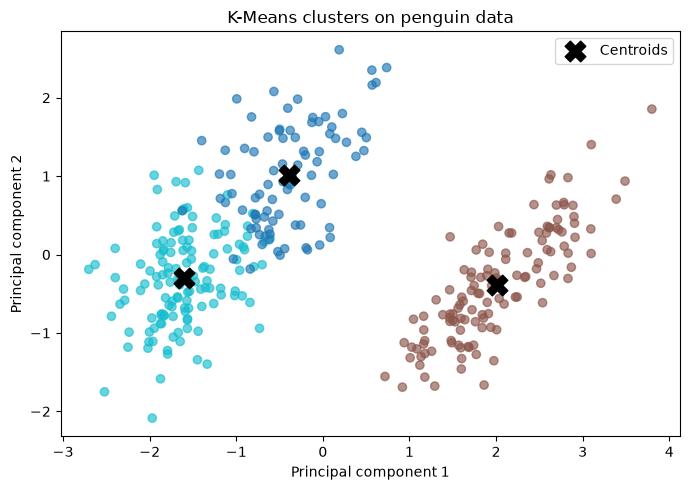

Silhouette score: 0.447
ARI against species (post-hoc only): 0.793
cluster     0    1    2
species                
Adelie     24    0  127
Chinstrap  63    0    5
Gentoo      0  123    0


In [8]:
centers_2d = pca.transform(kmeans.cluster_centers_)
plt.figure(figsize=(7,5))
plt.scatter(X2[:,0], X2[:,1], c=clusters, cmap="tab10", alpha=0.65)
plt.scatter(centers_2d[:,0], centers_2d[:,1], marker="X", s=220, c="black", label="Centroids")
plt.title("K-Means clusters on penguin data")
plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")
plt.legend(); plt.tight_layout(); plt.show()

from sklearn.metrics import silhouette_score, adjusted_rand_score
print("Silhouette score:", round(silhouette_score(X, clusters), 3))
print("ARI against species (post-hoc only):", round(adjusted_rand_score(penguins["species"], clusters), 3))
print(pd.crosstab(penguins["species"], penguins["cluster"]))

<div dir="rtl" style="direction: rtl; text-align: right;">


## ۳) SOM — نقشه‌ی خودسازمان‌ده (Self-Organizing Map)

### چرا SOM، وقتی K-Means را داریم؟
K-Means هر نمونه را به یکی از K خوشه‌ها اختصاص می‌دهد و مرکز آن خوشه‌ها را پیدا می‌کند. SOM نیز بدون برچسب آموزش می‌بیند، اما خروجی آن یک **شبکه‌ی دوبعدی از نورون‌ها** است. هر نورون یک بردار وزن با همان تعداد ویژگی ورودی دارد. هر نمونه به نورون برنده نگاشت می‌شود و نورون‌های نزدیک به برنده نیز هنگام آموزش به سمت آن نمونه حرکت می‌کنند.

SOM تلاش می‌کند همسایگی داده‌ها را روی صفحه حفظ کند: نمونه‌های مشابه ترجیحاً روی نورون‌های نزدیک قرار می‌گیرند. این ویژگی برای دیدن ساختار و گذار میان گروه‌ها مفید است؛ اما تضمین نمی‌کند که هر مرز دوبعدی دقیقاً یک کلاس واقعی باشد.

در این بخش از همان X استفاده می‌کنیم: چهار ویژگی پنگوئن که قبلاً پاک‌سازی و استاندارد شده‌اند. بنابراین تفاوت خروجی K-Means و SOM ناشی از نوع الگوریتم و نمایش آن‌هاست، نه تفاوت داده‌ی ورودی. ستون species در آموزش SOM استفاده نمی‌شود.


</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

### ساخت و آموزش SOM: معنی پارامترها

یک نقشه‌ی 8×8 می‌سازیم؛ یعنی ۶۴ نورون داریم. چون هر نمونه در X چهار ویژگی دارد، بردار وزن هر نورون نیز چهار مؤلفه خواهد داشت. شکل وزن‌های مدل برابر (8, 8, 4) است.

- **SOM_ROWS=8 و SOM_COLS=8:** تعداد سطر و ستون شبکه. نقشه‌ی بزرگ‌تر ظرفیت نمایش جزئیات بیشتری دارد، ولی ممکن است نورون‌های خالی بیشتری داشته باشد.
- **input_len=X.shape[1]:** تعداد ویژگی‌های ورودی؛ باید با تعداد ستون‌های X برابر باشد.
- **sigma=2.0:** شعاع همسایگی اولیه؛ در شروع نورون‌های دورتر نیز تا حدی از برنده تأثیر می‌گیرند.
- **learning_rate=0.5:** اندازه‌ی گام حرکت وزن‌ها به سمت نمونه.
- **random_seed=42:** بذر ثابت برای مقداردهی اولیه‌ی تکرارپذیر.
- **SOM_ITERATIONS=20000:** تعداد گام‌های آموزش؛ برای ۳۴۲ نمونه تقریباً ۵۸ انتخاب نمونه به‌ازای هر نمونه است، نه لزوماً ۵۸ epoch.

برای شروع، وزن‌ها را با **PCA initialization** مقداردهی می‌کنیم. این روش از جهت‌های اصلی تغییرات داده برای چیدن اولیه‌ی وزن‌ها استفاده می‌کند و معمولاً شروع منظم‌تری از انتخاب تصادفی نمونه‌ها می‌دهد. سپس train_random نمونه‌ها را انتخاب می‌کند. در هر گام، وزن نورون برنده و همسایه‌هایش در جهت نمونه حرکت می‌کنند:
</div>

$$
w_i(t+1) = w_i(t) + \alpha(t)h_{ci}(t) (x-w_i(t))
$$
<div dir="rtl" style="direction: rtl; text-align: right;">

در این رابطه x نمونه‌ی ورودی، c نورون برنده، α نرخ یادگیری و h میزان اثر همسایگی نورون i نسبت به برنده است.

**Quantization error** میانگین فاصله‌ی هر نمونه تا وزن نورون برنده‌ی خودش است:
</div>

$$
QE=\frac{1}{N}\sum_{j=1}^{N}\left\|x_j-w_{BMU(j)}\right\|_2
$$

<div dir="rtl" style="direction: rtl; text-align: right;">

هرچه کمتر باشد، وزن نورون‌های برنده به نمونه‌ها نزدیک‌تر است؛ اما این معیار به‌تنهایی نمی‌گوید آیا همسایگی و توپولوژی نقشه خوب حفظ شده است یا نه. برای مانور، یک شبکه‌ی کوچک مثل ۳×۳ را با ۸×۸ مقایسه کنید. تغییر sigma و learning rate را همراه با Quantization Error و occupancy بررسی کنید.

</div>

In [16]:
from minisom import MiniSom

# Main SOM settings. Adjust these to experiment with map size and learning behavior.
SOM_ROWS = 8
SOM_COLS = 8
SOM_ITERATIONS = 20000
SOM_SIGMA = 2.0
SOM_LEARNING_RATE = 0.5
SOM_RANDOM_SEED = 42

som = MiniSom(
    SOM_ROWS,
    SOM_COLS,
    X.shape[1],
    sigma=SOM_SIGMA,
    learning_rate=SOM_LEARNING_RATE,
    random_seed=SOM_RANDOM_SEED
)

# PCA initialization gives the map a structured starting layout.
som.pca_weights_init(X)
som.train_random(X, SOM_ITERATIONS, verbose=False)

print("SOM map shape:", som.get_weights().shape)
print("Training iterations:", SOM_ITERATIONS)
print("Initialization: PCA")
print("Sigma:", SOM_SIGMA, "| Learning rate:", SOM_LEARNING_RATE)
print("Quantization error:", round(som.quantization_error(X), 4))


SOM map shape: (8, 8, 4)
Training iterations: 20000
Initialization: PCA
Sigma: 2.0 | Learning rate: 0.5
Quantization error: 0.4455


<div dir="rtl" style="direction: rtl; text-align: right;">


### BMU و نگاشت نمونه‌ها روی نقشه

BMU مخفف Best Matching Unit یا «واحد با بهترین تطابق» است. برای هر نمونه x، نورونی را پیدا می‌کنیم که بردار وزنش کمترین فاصله‌ی اقلیدسی را با آن دارد:
</div>

$
BMU(x)=\arg\min_i\|x-w_i\|_2
$

<div dir="rtl" style="direction: rtl; text-align: right;">

کد بعدی مختصات سطر و ستون BMU هر پنگوئن را به دست می‌آورد و نمونه را در محل همان نورون رسم می‌کند. رنگ از species می‌آید، اما **فقط برای تفسیر پس از آموزش** استفاده می‌شود؛ گونه‌ها در ساخت SOM یا پیدا کردن BMU وارد نشده‌اند.

چند نمونه ممکن است BMU یکسان داشته باشند و روی هم بیفتند. به همین دلیل jitter کوچکی فقط به مختصات رسم اضافه می‌کنیم تا نقاط دیده شوند. این جابه‌جایی ظاهری، داده، وزن‌ها یا BMU واقعی را تغییر نمی‌دهد.


</div>

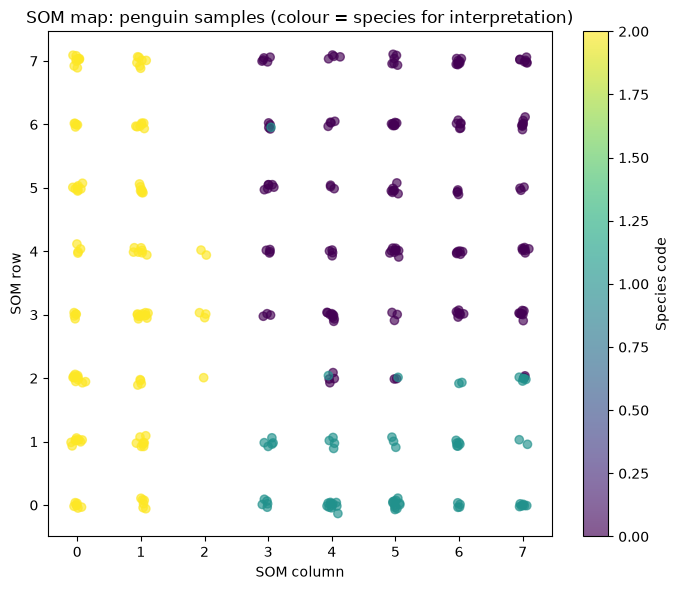

In [10]:
# Rebuild and train the SOM if the training cell was skipped or the kernel restarted.
if "som" not in globals():
    from minisom import MiniSom
    SOM_ROWS, SOM_COLS, SOM_ITERATIONS = 8, 8, 20000
    SOM_SIGMA, SOM_LEARNING_RATE, SOM_RANDOM_SEED = 2.0, 0.5, 42
    som = MiniSom(
        SOM_ROWS, SOM_COLS, X.shape[1],
        sigma=SOM_SIGMA,
        learning_rate=SOM_LEARNING_RATE,
        random_seed=SOM_RANDOM_SEED
    )
    som.pca_weights_init(X)
    som.train_random(X, SOM_ITERATIONS, verbose=False)

winners = np.array([som.winner(row) for row in X], dtype=int)
jitter_rng = np.random.default_rng(42)
jitter_x = jitter_rng.normal(0, 0.045, len(X))
jitter_y = jitter_rng.normal(0, 0.045, len(X))

plt.figure(figsize=(7, 6))
plt.scatter(
    winners[:, 1] + jitter_x,
    winners[:, 0] + jitter_y,
    c=penguins["species"].astype("category").cat.codes,
    cmap="viridis",
    alpha=0.65
)
plt.title("SOM map: penguin samples (colour = species for interpretation)")
plt.xlabel("SOM column")
plt.ylabel("SOM row")
plt.colorbar(label="Species code")
plt.tight_layout()
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right;">


### U-Matrix و نقشه‌ی اشغال نورون‌ها

U-Matrix اختلاف بردار وزن یک نورون با همسایه‌هایش را نشان می‌دهد. در این کد همسایه‌های مستقیم بالا، پایین، چپ و راست را بررسی می‌کنیم و **میانگین فاصله‌ی اقلیدسی** را حساب می‌کنیم:
$
U(r,c)=\operatorname{mean}_{j\in Neighbours(r,c)}
\|w_{r,c}-w_j\|_2
$
مقدار بزرگ‌تر می‌تواند نشانه‌ی مرزی میان نواحی متفاوت نقشه باشد. مقدارهای کوچک‌تر یعنی بردار وزن نورون و همسایه‌هایش شبیه‌ترند. سپس U-Matrix را بر بیشینه‌ی خودش تقسیم می‌کنیم تا برای نمایش به بازه‌ی صفر تا یک برود. این تصویر برچسب خوشه نیست و نباید هر ناحیه‌ی روشن را یک کلاس قطعی بدانیم.

نمودار دوم **occupancy** را نشان می‌دهد: چند نمونه BMU هر نورون شده‌اند. خانه‌ی صفر یعنی هیچ نمونه‌ای به آن نورون نگاشت نشده؛ عدد بزرگ یعنی نمونه‌های بیشتری روی آن نورون جمع شده‌اند. پس U-Matrix اختلاف وزن همسایه‌ها را نشان می‌دهد و occupancy میزان استفاده از نورون‌ها را.

در انتها تعداد نورون‌های اشغال‌شده را گزارش می‌کنیم. Silhouette که در خط آخر چاپ می‌شود معیار K-Means است و اینجا فقط برای مقایسه‌ی مرجع آمده؛ معیار مستقیم SOM نیست.


</div>

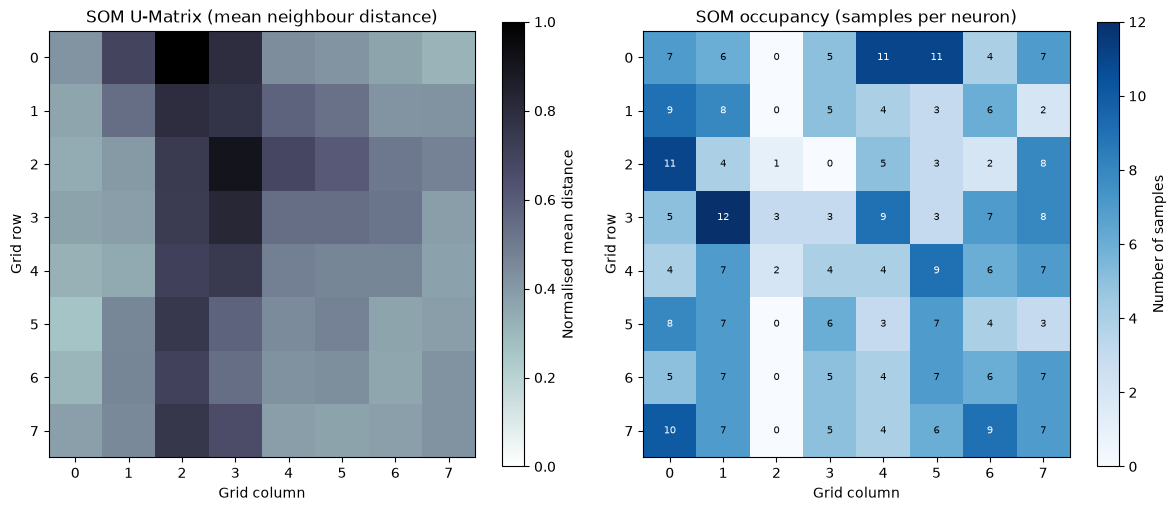

SOM occupied neurons: 58 of 64
SOM empty neurons: 6
Maximum occupancy: 12
Quantization error: 0.4455
K-Means silhouette (reference only): 0.447
Interpretation: U-Matrix shows local weight differences; occupancy shows how samples are distributed over the map.


In [11]:
weights = som.get_weights()
map_rows, map_cols = weights.shape[:2]
u_matrix = np.zeros((map_rows, map_cols), dtype=float)
occupancy = np.zeros((map_rows, map_cols), dtype=int)

for row_idx, col_idx in winners:
    occupancy[row_idx, col_idx] += 1

# Average distance to the four orthogonal neighbours that exist at each cell.
for r in range(map_rows):
    for c in range(map_cols):
        neighbour_distances = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            rr, cc = r + dr, c + dc
            if 0 <= rr < map_rows and 0 <= cc < map_cols:
                neighbour_distances.append(
                    np.linalg.norm(weights[r, c] - weights[rr, cc])
                )
        u_matrix[r, c] = np.mean(neighbour_distances)

# Normalize only for visual contrast; the printed QE remains in original scaled units.
if u_matrix.max() > 0:
    u_matrix = u_matrix / u_matrix.max()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(
    u_matrix, cmap="bone_r", interpolation="nearest", vmin=0, vmax=1
)
axes[0].set_title("SOM U-Matrix (mean neighbour distance)")
axes[0].set_xlabel("Grid column")
axes[0].set_ylabel("Grid row")
plt.colorbar(im0, ax=axes[0], label="Normalised mean distance")

im1 = axes[1].imshow(
    occupancy, cmap="Blues", interpolation="nearest", vmin=0
)
axes[1].set_title("SOM occupancy (samples per neuron)")
axes[1].set_xlabel("Grid column")
axes[1].set_ylabel("Grid row")
for r in range(map_rows):
    for c in range(map_cols):
        axes[1].text(
            c, r, str(occupancy[r, c]), ha="center", va="center", fontsize=7,
            color="black" if occupancy[r, c] < occupancy.max() * 0.65 else "white"
        )
plt.colorbar(im1, ax=axes[1], label="Number of samples")
plt.tight_layout()
plt.show()

occupied_count = int((occupancy > 0).sum())
print("SOM occupied neurons:", occupied_count, "of", occupancy.size)
print("SOM empty neurons:", int((occupancy == 0).sum()))
print("Maximum occupancy:", int(occupancy.max()))
print("Quantization error:", round(som.quantization_error(X), 4))
print("K-Means silhouette (reference only):", round(silhouette_score(X, clusters), 3))
print("Interpretation: U-Matrix shows local weight differences; occupancy shows how samples are distributed over the map.")


<div dir="rtl" style="direction: rtl; text-align: right;">


## ۴) Hopfield — حافظه‌ی انجمنی و بازیابی الگو

### مسئله و ایده‌ی شبکه
شبکه‌ی Hopfield یک حافظه‌ی انجمنی بازگشتی است. برخلاف یک طبقه‌بند معمولی، هدف اصلی آن نگاشت مستقیم ورودی به نام کلاس نیست؛ چند الگو را در ماتریس وزن ذخیره می‌کند. اگر نسخه‌ای خراب‌شده از یک الگوی ذخیره‌شده وارد کنیم، شبکه با به‌روزرسانی حالت نورون‌ها تلاش می‌کند به یک حالت پایدار نزدیک شود. اگر شرایط مناسب باشد، آن حالت می‌تواند همان الگوی ذخیره‌شده باشد.

در این مثال از رقم‌های ۰ و ۴ در تصویرهای ۸×۸ استفاده می‌کنیم؛ هر پیکسل یک نورون است، پس هر تصویر ۶۴ نورون دارد. فقط دو الگو را ذخیره می‌کنیم تا نمایش ساده بماند و تداخل حافظه کم باشد. ظرفیت Hopfield محدود است؛ ذخیره‌ی تعداد زیادی الگوی مشابه در شبکه‌ی کوچک می‌تواند بازیابی اشتباه یا حالت‌های پایدار ناخواسته ایجاد کند.

این مثال کوچک برای فهم حافظه و انرژی است. کاربرد پروژه‌ی اصلی متفاوت است: در آنجا از الگوی مرجع تابلوی سرعت استفاده می‌شود و تغییرات مصنوعی با بازیابی و سنجش تفاوت غربال می‌شوند.


</div>

<div dir="rtl" style="direction: rtl; text-align: right;">


### دریافت تصویرها و تبدیل به الگوی دوقطبی

تابع load_digits تصویرهای کوچک خاکستری را در اختیار می‌گذارد. یک نمونه از رقم ۰ و یک نمونه از رقم ۴ انتخاب می‌کنیم. تصویرها ۸×۸ هستند و شدت هر پیکسل بین صفر و ۱۶ قرار دارد.

Hopfield کلاسیک دودویی با دو حالت -1 و +1 کار می‌کند، نه شدت خاکستری پیوسته. بنابراین آستانه‌ی ۸ می‌گذاریم: پیکسل با شدت حداقل ۸ به +1 و پیکسل کم‌نورتر به -1 تبدیل می‌شود. هر تصویر در نتیجه به برداری با ۶۴ مؤلفه تبدیل می‌شود؛ هر مؤلفه حالت یک نورون است.

کد این سلول تصویرهای انتخاب‌شده را رسم می‌کند و بردارهای دوقطبی را در فهرست patterns جمع می‌کند. در این نقطه هنوز شبکه ساخته نشده است؛ فقط نمونه‌های حافظه را آماده می‌کنیم.


</div>

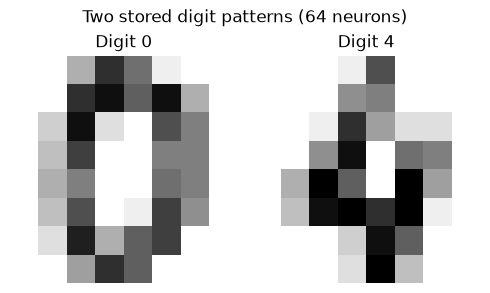

In [12]:
from sklearn.datasets import load_digits

digits = load_digits()
# Two well-separated memories keep this 64-neuron demonstration below its
# practical storage limit. The assignment applies Hopfield to a single sign prototype.
chosen = [0, 4]
patterns = []
fig, axes = plt.subplots(1, len(chosen), figsize=(5, 3))
for ax, digit in zip(axes, chosen):
    image = digits.images[np.where(digits.target == digit)[0][0]]
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
    patterns.append(np.where(image.ravel() >= 8, 1, -1))

plt.suptitle("Two stored digit patterns (64 neurons)")
plt.tight_layout()
plt.show()


<div dir="rtl" style="direction: rtl; text-align: right;">


### ذخیره‌ی الگوها در ماتریس وزن

هر ردیف patterns یک الگوی ۶۴تایی است. ماتریس وزن با قاعده‌ی Hebbian ساخته می‌شود:
$
W=\frac{1}{N}\sum_{\mu=1}^{P}\xi^{(\mu)}(\xi^{(\mu)})^T
$
که N=64 تعداد نورون‌ها، P=2 تعداد الگوهای ذخیره‌شده و ξ الگوی ذخیره‌شده است. دستور patterns.T @ patterns / n همین جمع حاصل‌ضرب‌های خارجی را محاسبه می‌کند.

- شکل W برابر 64×64 است؛ هر درایه وزن ارتباط دو نورون را نشان می‌دهد.
- W باید متقارن باشد: \(W_{ij}=W_{ji}\).
- قطر را صفر می‌کنیم: \(W_{ii}=0\). در نتیجه نورون به خودش وصل نیست و هنگام محاسبه‌ی انرژی تغییر حالت خودش را از طریق وزن خودی دریافت نمی‌کند.

این شبکه بعد از ساخت W حافظه‌ی خود را در همان وزن‌ها نگه می‌دارد؛ در این مثال مرحله‌ی fit یعنی ساخت همین ماتریس است.


</div>

In [13]:
patterns = np.asarray(patterns, dtype=np.int8)
n = patterns.shape[1]
W = patterns.T @ patterns / n
np.fill_diagonal(W, 0)

print("Stored memories:", len(patterns))
print("Neurons per memory:", n)
print("Weight shape:", W.shape)
print("Weight matrix symmetric:", bool(np.allclose(W, W.T)))
print("Zero diagonal:", bool(np.all(np.diag(W) == 0)))


Stored memories: 2
Neurons per memory: 64
Weight shape: (64, 64)
Weight matrix symmetric: True
Zero diagonal: True


<div dir="rtl" style="direction: rtl; text-align: right;">


### ورودی نویزی، بازیابی ناهم‌زمان و انرژی شبکه

تابع انرژی شبکه را به شکل زیر تعریف می‌کنیم:
$
E(s)=-\frac{1}{2}s^TWs
$
که s بردار حالت فعلی نورون‌ها و W ماتریس وزن است.

برای هر نورون i میدان محلی را محاسبه می‌کنیم:
$
h_i=\sum_j W_{ij}s_j
$
اگر h مثبت باشد نورون +1 و اگر منفی باشد -1 می‌شود؛ اگر صفر باشد حالت قبلی را نگه می‌داریم. در **به‌روزرسانی ناهم‌زمان** در هر لحظه فقط یک نورون تغییر می‌کند. ترتیب نورون‌ها در هر دور تصادفی است، ولی seed ثابت باعث تکرارپذیری آزمایش می‌شود. پارامتر sweeps=20 یعنی حداکثر ۲۰ دور کامل؛ در هر دور ترتیب همه‌ی ۶۴ نورون به‌صورت تصادفی پیموده می‌شود و هر نورون فرصت یک به‌روزرسانی دارد. اگر پس از یک دور هیچ نورونی تغییر نکند، حلقه زودتر متوقف می‌شود. تابع recall در پایان هم حالت بازیابی‌شده و هم فهرست انرژی پس از هر به‌روزرسانی را برمی‌گرداند.

با وزن متقارن و قطر صفر، تغییر یک نورون در هر بار باعث می‌شود انرژی افزایش نیابد؛ ممکن است کم شود یا ثابت بماند. این ویژگی دلیل استفاده از انرژی در این مثال است: می‌توانیم بررسی کنیم پویایی شبکه با انتظار نظری سازگار است یا نه. کاهش انرژی به‌تنهایی تضمین نمی‌کند که شبکه حتماً به الگوی موردنظر برسد؛ ممکن است به یک حالت پایدار دیگر هم برسد.

برای آزمایش، ۲۰٪ از ۶۴ بیت الگوی ذخیره‌شده را تصادفی برعکس می‌کنیم؛ یعنی علامت پیکسل‌های انتخاب‌شده از +1 به -1 یا برعکس تغییر می‌کند. سپس سه تصویر را کنار هم می‌بینیم: الگوی اصلی، ورودی خراب‌شده و خروجی بازیابی‌شده.

**Bitwise recovery accuracy** سهم بیت‌هایی است که خروجی با الگوی هدف برابر دارد:
$
Accuracy=\frac{\text{تعداد بیت‌های برابر}}{64}
$
عدد ۱ یعنی هر ۶۴ پیکسل درست بازیابی شده‌اند. نمودار انرژی نیز باید غیرصعودی باشد و assert این شرط را خودکار بررسی می‌کند.


</div>

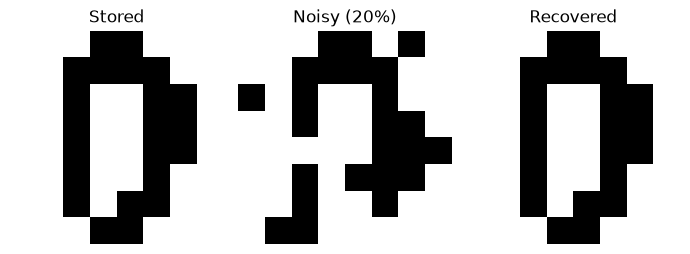

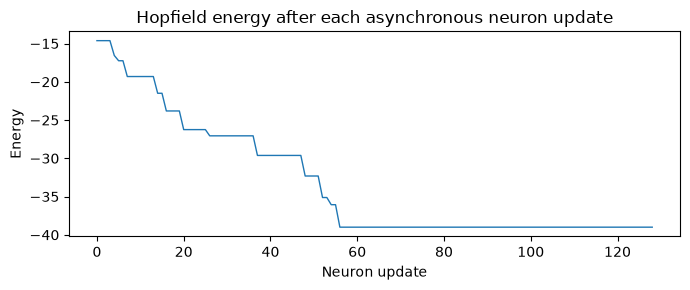

Bitwise recovery accuracy: 1.0
Energy non-increasing at every neuron update: True
Initial energy: -14.625
Final energy: -39.0


In [18]:
def energy(state):
    state = np.asarray(state, dtype=np.float64)
    return float(-0.5 * state @ W @ state)


def recall(state, sweeps=20, seed=12345678):
    rng = np.random.default_rng(seed)
    state = np.asarray(state, dtype=np.int8).copy()
    history = [energy(state)]

    for _ in range(sweeps):
        before = state.copy()
        # Asynchronous updates: one neuron is changed at a time.
        for i in rng.permutation(n):
            local_field = W[i] @ state
            if local_field > 0:
                state[i] = 1
            elif local_field < 0:
                state[i] = -1
            history.append(energy(state))
        if np.array_equal(before, state):
            break
    return state, history


target = patterns[0].copy()
rng = np.random.default_rng(9)
noisy = target.copy()
flip = rng.choice(n, size=int(0.20 * n), replace=False)
noisy[flip] *= -1
recovered, history = recall(noisy, seed=12345678)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, arr, title in zip(axes, [target, noisy, recovered], ["Stored", "Noisy (20%)", "Recovered"]):
    ax.imshow(arr.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(history, linewidth=1)
plt.title("Hopfield energy after each asynchronous neuron update")
plt.xlabel("Neuron update")
plt.ylabel("Energy")
plt.tight_layout()
plt.show()

recovery_accuracy = float(np.mean(target == recovered))
energy_monotone = bool(np.all(np.diff(history) <= 1e-9))
print("Bitwise recovery accuracy:", round(recovery_accuracy, 3))
print("Energy non-increasing at every neuron update:", energy_monotone)
print("Initial energy:", round(history[0], 3))
print("Final energy:", round(history[-1], 3))
assert energy_monotone, "Energy increased during asynchronous recall."

<div dir="rtl" style="direction: rtl; text-align: right;">


### آزمایش تکمیلی: حساسیت بازیابی به میزان خرابی

یک آزمایش موفق به‌تنهایی کافی نیست؛ نتیجه ممکن است به تعداد بیت‌های خراب یا محل تصادفی آن‌ها وابسته باشد. برای همین نرخ خرابی را روی ۱۰٪، ۲۰٪ و ۳۰٪ آزمایش می‌کنیم. برای هر نرخ، هر دو الگوی ذخیره‌شده را ۱۰ بار با محل خرابی متفاوت امتحان می‌کنیم؛ در مجموع 3×2×10 یعنی ۶۰ آزمایش داریم.

در هر تکرار:
1. از الگوی سالم یک کپی می‌سازیم.
2. تعداد مشخصی از ۶۴ پیکسل را بدون جایگذاری انتخاب می‌کنیم و علامت آن‌ها را برعکس می‌کنیم.
3. بازیابی Hopfield را اجرا می‌کنیم.
4. دقت پیکسلی، بازیابی کاملاً دقیق و غیرصعودی‌بودن انرژی را ثبت می‌کنیم.

در جدول:
- mean_pixel_accuracy: میانگین سهم پیکسل‌های درست در همه‌ی آزمایش‌های آن نرخ.
- exact_recalls: تعداد دفعاتی که تمام ۶۴ پیکسل دقیقاً بازیابی شده‌اند.
- trials: تعداد آزمایش‌ها؛ برای هر نرخ باید ۲۰ باشد.
- all_energy_traces_monotone: آیا انرژی در همه‌ی آزمایش‌های آن نرخ غیرصعودی مانده است؟

به دلیل int(noise_rate * n)، تعداد بیت‌ها به عدد صحیح گرد می‌شود؛ بنابراین درصد واقعی خرابی ممکن است کمی با ۱۰، ۲۰ یا ۳۰ درصد تفاوت داشته باشد. با افزایش خرابی معمولاً بازیابی دشوارتر می‌شود، اما نتیجه به الگوها و محل بیت‌های خراب وابسته است. این آزمایش بازیابی حافظه است و با threshold تشخیص anomaly در مسئله‌ی تابلوی سرعت یکی نیست.


</div>

In [21]:
noise_records = []
for noise_rate in [0.10, 0.20, 0.30, .4, .5, .6]:
    for pattern_idx, clean_pattern in enumerate(patterns):
        for trial in range(10):
            noise_rng = np.random.default_rng(10000 + pattern_idx * 100 + trial)
            corrupted = clean_pattern.copy()
            flip_count = int(noise_rate * n)
            flip_indices = noise_rng.choice(n, size=flip_count, replace=False)
            corrupted[flip_indices] *= -1

            recalled, energy_trace = recall(
                corrupted, sweeps=20, seed=12345678 + pattern_idx * 100 + trial
            )
            noise_records.append({
                "noise_rate": noise_rate,
                "stored_digit": chosen[pattern_idx],
                "trial": trial,
                "pixel_accuracy": np.mean(recalled == clean_pattern),
                "exact_recall": bool(np.array_equal(recalled, clean_pattern)),
                "energy_non_increasing": bool(np.all(np.diff(energy_trace) <= 1e-9))
            })

noise_results = pd.DataFrame(noise_records)
noise_summary = noise_results.groupby("noise_rate").agg(
    mean_pixel_accuracy=("pixel_accuracy", "mean"),
    exact_recalls=("exact_recall", "sum"),
    trials=("exact_recall", "count"),
    all_energy_traces_monotone=("energy_non_increasing", "all")
)
display(noise_summary.round(3))

,mean_pixel_accuracy,exact_recalls,trials,all_energy_traces_monotone
noise_rate,,,,
0.1,1.000,20,20,True
0.2,1.000,20,20,True
0.3,1.000,20,20,True
0.4,0.938,15,20,True
0.5,0.512,0,20,True
0.6,0.100,0,20,True


<div dir="rtl" style="direction: rtl; text-align: right;">


## پرسش‌های راهنمای آموزشی

1. **سری زمانی:** چرا تقسیم تصادفی داده به آموزش و آزمون ممکن است اطلاعات آینده را وارد آموزش کند؟ چرا rolling_7 را با shift(1) می‌سازیم؟
2. **سری زمانی:** اگر MAE بهتر شود ولی RMSE خیلی بزرگ بماند، درباره‌ی وجود خطاهای بزرگ چه برداشتی می‌کنید؟
3. **K-Means:** چرا مقیاس‌بندی برای فاصله‌ی اقلیدسی مهم است؟ اگر جرم بدن بر حسب گرم و طول باله بر حسب میلی‌متر باشد، کدام ویژگی می‌تواند بر فاصله غالب شود؟
4. **PCA:** چرا K-Means را روی X چهاربعدی اجرا می‌کنیم ولی X2 دوبعدی را برای نمودار به کار می‌بریم؟ اگر مدل را روی X2 آموزش دهیم چه اطلاعاتی ممکن است از دست برود؟
5. **K-Means:** تفاوت Silhouette و ARI چیست؟ کدام‌یک بدون برچسب واقعی محاسبه می‌شود؟
6. **K-Means:** چرا شماره‌ی خوشه معنای ذاتی ندارد و چرا نباید species را هنگام fit وارد کنیم؟
7. **SOM:** BMU چگونه انتخاب می‌شود و چرا نورون‌های اطراف آن نیز در آموزش تغییر می‌کنند؟
8. **SOM:** تفاوت U-Matrix با occupancy چیست؟ نورون با occupancy صفر چه معنایی دارد؟
9. **Hopfield:** چرا تصویر را به -1 و +1 تبدیل می‌کنیم؟ چرا قطر ماتریس وزن صفر می‌شود؟
10. **Hopfield:** چرا به‌روزرسانی ناهم‌زمان با وزن متقارن باعث می‌شود انرژی افزایش پیدا نکند؟ آیا کاهش انرژی تضمین می‌کند که حتماً به الگوی موردنظر می‌رسیم؟


</div>

<div dir="rtl" style="direction: rtl; text-align: right;">


## جمع‌بندی: از داده تا نتیجه

| بخش | ورودی مدل | هدف | معیار یا ابزار تفسیر |
|---|---|---|---|
| سری زمانی | ویژگی‌های ساخته‌شده از گذشته | پیش‌بینی مقدار آینده | MAE، RMSE و نمودار پیش‌بینی |
| K-Means | ویژگی‌های عددی استانداردشده | گروه‌بندی نمونه‌های مشابه | Inertia، Silhouette و در صورت وجود مرجع، ARI |
| SOM | همان ویژگی‌های استانداردشده | نگاشت داده روی شبکه‌ی دوبعدی | BMU، Quantization Error، U-Matrix و occupancy |
| Hopfield | الگوهای دوقطبی | بازیابی الگوی ذخیره‌شده | دقت بازیابی و تغییرات انرژی |

معیارها به پرسش‌های متفاوتی پاسخ می‌دهند: MAE و RMSE کیفیت پیش‌بینی عددی را می‌سنجند؛ Silhouette جدایی خوشه‌ها را بدون برچسب واقعی بررسی می‌کند؛ ARI توافق خوشه‌بندی با یک مرجع را می‌سنجد؛ Quantization Error نزدیکی نمونه‌ها به نورون‌های برنده‌ی SOM را بررسی می‌کند؛ و انرژی Hopfield رفتار پویایی بازیابی را کنترل می‌کند. هیچ‌کدام را نباید بدون توجه به نوع مسئله به‌جای دیگری استفاده کرد.


</div>